<a href="https://colab.research.google.com/github/Mihret4204/math4ai/blob/main/Math_for_AI_lab_3_2019.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# 🎧 **Lab 3: Audio Data and Linear Algebra**

## **Introduction**

In the previous laboratory, we explored how digital images are represented as numerical arrays and manipulated using NumPy.

In this laboratory, we will explore how digital audio recordings are represented as vectors and matrices, and how fundamental linear algebra operations can be used to analyze and manipulate audio signals.

Through hands-on demonstrations and exercises, we will load and play real audio recordings, visualize waveforms, extract audio segments, adjust amplitudes, mix recordings, add noise, and work with mono and stereo audio.

## **Learning Objectives**

By the end of this laboratory, students should be able to:

1. Explain the basic principles of digital audio, including sampling, quantization, and binary representation.
2. Understand sampling rate, audio duration, and the relationship between sample indices and time.
3. Represent mono audio as a vector and stereo audio as a matrix.
4. Load, visualize, play, and extract segments from digital audio recordings.
5. Apply scalar multiplication, normalization, and vector addition to manipulate audio signals.
6. Compute vector norms, root mean square (RMS), and signal-to-noise ratio (SNR) to measure audio signal strength and noise.
7. Construct stereo recordings, extract individual audio channels, and convert stereo audio to mono.

------------------
--------------------------------------------------------------------------------

In [ ]:
#@title Lab 3 Utilities (Run Once) { display-mode: "form" }

# ============================================================
# LAB 3: AUDIO DATA AND LINEAR ALGEBRA
# Reusable Utility Functions
# ============================================================

# ------------------------------------------------------------
# 1. Libraries
# ------------------------------------------------------------

import numpy as np
import matplotlib.pyplot as plt
import librosa

from IPython.display import Audio, display


# ------------------------------------------------------------
# 2. Audio Playback
# ------------------------------------------------------------

def play_audio(signal, sr=16000, normalize=False):
    """Play mono or stereo audio."""

    signal = np.asarray(signal)

    # Convert (samples, channels) to (channels, samples)
    if signal.ndim == 2 and signal.shape[1] == 2:
        signal = signal.T

    # Preserve amplitude differences during playback
    if not normalize:
        signal = np.clip(signal, -1.0, 1.0)

    display(Audio(signal, rate=sr, normalize=normalize))


# ------------------------------------------------------------
# 3. Plot a Single Audio Waveform
# ------------------------------------------------------------

def plot_waveform(signal, sr=16000,
                  title="Audio Waveform", highlight=None):
    """Plot a mono waveform with optional time highlighting."""

    signal = np.asarray(signal)
    time = np.arange(len(signal)) / sr

    plt.figure(figsize=(12, 3))
    plt.plot(time, signal, linewidth=0.7)

    if highlight is not None:
        start_time, end_time = highlight

        plt.axvspan(
            start_time, end_time,
            color="orange",
            alpha=0.3,
            label="Selected Segment"
        )
        plt.legend()

    plt.xlabel("Time (seconds)")
    plt.ylabel("Amplitude")
    plt.title(title)
    plt.grid(alpha=0.3)
    plt.show()


# ------------------------------------------------------------
# 4. Compare Multiple Audio Waveforms
# ------------------------------------------------------------

def compare_waveforms(signals, titles, sr=16000, ylim=None):
    """Plot multiple mono signals with a shared amplitude scale."""

    if len(signals) != len(titles):
        raise ValueError(
            "Each signal must have a corresponding title."
        )

    n = len(signals)

    if n == 0:
        raise ValueError("At least one signal is required.")

    if ylim is None:
        max_amplitude = max(
            np.max(np.abs(s)) for s in signals
        )
        limit = max(1.0, max_amplitude * 1.05)
        ylim = (-limit, limit)

    fig, axes = plt.subplots(
        n, 1,
        figsize=(12, 2.2 * n),
        sharex=True,
        squeeze=False
    )

    for ax, signal, title in zip(
        axes[:, 0], signals, titles
    ):
        time = np.arange(len(signal)) / sr

        ax.plot(time, signal, linewidth=0.6)
        ax.set_title(title)
        ax.set_ylabel("Amplitude")
        ax.set_ylim(ylim)
        ax.grid(alpha=0.3)

    axes[-1, 0].set_xlabel("Time (seconds)")

    plt.tight_layout()
    plt.show()


# ------------------------------------------------------------
# 5. Sampling and Quantization Visualization
# ------------------------------------------------------------

def plot_sampling_quantization(
    t_continuous,
    x_continuous,
    t_samples,
    x_samples,
    x_quantized,
    bits
):
    """Compare sampling and amplitude quantization."""

    fig, axes = plt.subplots(
        2, 1,
        figsize=(11, 6),
        sharex=True
    )

    # Sampling
    axes[0].plot(
        t_continuous,
        x_continuous,
        label="Continuous-time model",
        color="tab:blue"
    )

    axes[0].stem(
        t_samples,
        x_samples,
        linefmt="tab:orange",
        markerfmt="ro",
        basefmt=" "
    )

    axes[0].set_title("Sampling a Continuous Signal")
    axes[0].set_ylabel("Amplitude")
    axes[0].legend()
    axes[0].grid(alpha=0.3)

    # Quantization
    axes[1].plot(
        t_continuous,
        x_continuous,
        color="lightgray",
        label="Original waveform"
    )

    axes[1].stem(
        t_samples,
        x_quantized,
        linefmt="tab:green",
        markerfmt="go",
        basefmt=" "
    )

    axes[1].set_title(
        f"Quantization: {bits} Bits ({2**bits} Levels)"
    )
    axes[1].set_xlabel("Time (seconds)")
    axes[1].set_ylabel("Amplitude")
    axes[1].legend()
    axes[1].grid(alpha=0.3)

    plt.tight_layout()
    plt.show()



## **1. From Analog Sound to Digital Audio**

Sound propagates through a medium as variations in pressure.

A microphone converts these pressure variations into an electrical signal, which can be modeled as a continuous function of time:

$$
x(t).
$$

Computers store and process digital values rather than arbitrary continuous signals.

Converting analog audio into digital audio involves three important operations:

### **1.1 Sampling**

Sampling measures the amplitude of a continuous signal at equally spaced time intervals.

If the sampling frequency is $f_s$ samples per second, then:

$$
x[n] = x\left(\frac{n}{f_s}\right),
\qquad n=0,1,\ldots,N-1.
$$

The time interval between consecutive samples is:

$$
\Delta t = \frac{1}{f_s}.
$$

For example, at a sampling rate of 16 kHz:

$$
f_s=16000 \text{ Hz}
$$

the signal is sampled 16,000 times per second.

The sampling interval is:

$$
\Delta t = \frac{1}{16000}
= 0.0000625 \text{ seconds}.
$$

For a recording lasting $T$ seconds, the number of samples is approximately:

$$
N=f_sT.
$$

A 5-second recording sampled at 16 kHz therefore contains:

$$
N=16000\times5=80000
$$

samples.


### **1.2 Quantization**

Sampling determines **when** the signal is measured.

Quantization determines **which numerical amplitude values** can be stored.

An analog signal can take continuously varying amplitude values, but a digital recording represents them using a finite set of levels.

If each sample is encoded using $b$ bits, there are:

$$
L=2^b
$$

possible binary codes.

For example:

- **3-bit audio:** $2^3=8$ possible levels.
- **8-bit audio:** $2^8=256$ possible levels.
- **16-bit audio:** $2^{16}=65536$ possible levels.

### Uniform Quantization

In uniform quantization, the available amplitude levels are equally spaced.

For an audio signal whose amplitudes lie in the interval $[-1,1]$, the distance between adjacent quantization levels is:

$$
\Delta=\frac{2}{L-1}.
$$

Each sampled amplitude $x_n$ is approximated by the nearest available quantization level.

The quantized amplitude is calculated as:

$$
q_n=
\frac{2}{L-1}
\operatorname{round}
\left(
\frac{(x_n+1)(L-1)}{2}
\right)-1.
$$

Here:

- $x_n$ is the original sampled amplitude.
- $q_n$ is the quantized amplitude.
- $L$ is the number of quantization levels.
- $\operatorname{round}(\cdot)$ rounds to the nearest integer.

The formula performs three operations:

1. **Scale:** Map the amplitude from $[-1,1]$ to $[0,L-1]$.
2. **Round:** Select the nearest integer representing a quantization level.
3. **Rescale:** Map the selected level back to the original amplitude interval $[-1,1]$.

For example, with $b=3$ bits:

$$
L=2^3=8,
\qquad
\Delta=\frac{2}{7}.
$$

The eight possible quantized amplitudes are:

$$
-1,\;-\frac{5}{7},\;-\frac{3}{7},\;-\frac{1}{7},
\;\frac{1}{7},\;\frac{3}{7},\;\frac{5}{7},\;1.
$$

Quantization introduces a difference between the original sampled amplitude and its quantized approximation.

This difference is called the **quantization error**:

$$
e_n=x_n-q_n.
$$


**Note:** This is a simplified uniform quantizer for educational purposes. Practical PCM audio formats may use different quantization ranges and encoding conventions.


### **1.3 Binary Encoding**

The quantized amplitude values are stored using binary digits (0 and 1).

For example, a signed 16-bit PCM sample might be stored as the integer:

$$
16384.
$$

When converted to a normalized floating-point representation, this can become:

$$
\frac{16384}{32768}=0.5.
$$

Thus, audio samples loaded into Python may appear as floating-point numbers such as:

$$
[0.12,\;0.35,\;-0.18,\;-0.42,\ldots].
$$

These values are still represented internally using binary digits.

**Important:** Sampling rate determines the temporal resolution of the recording, while bit depth determines the number of amplitude levels available in a fixed-point PCM representation.

(***Pulse Code Modulation (PCM)** is a method of representing an analog audio signal digitally by sampling its amplitude at regular intervals, quantizing the measured values, and encoding them as binary numbers.*)


In [ ]:
# ============================================================
# Demonstration: Sampling and Quantization
# ============================================================

# Signal parameters
frequency = 5
duration = 1.0

# Dense points to approximate a continuous waveform
t_continuous = np.linspace(0, duration, 2000, endpoint=False)

x_continuous = np.sin(2 * np.pi * frequency * t_continuous)


In [ ]:
# ------------------------------------------------------------
# 1. Sampling
# ------------------------------------------------------------

fs = 40

t_samples = np.arange(0, duration, 1 / fs)

x_samples = np.sin(2 * np.pi * frequency * t_samples)

In [ ]:
# ------------------------------------------------------------
# 2. Quantization
# ------------------------------------------------------------

bits = 3
levels = 2 ** bits

x_quantized = (np.round((x_samples + 1) * (levels - 1) / 2)* 2 / (levels - 1)- 1)

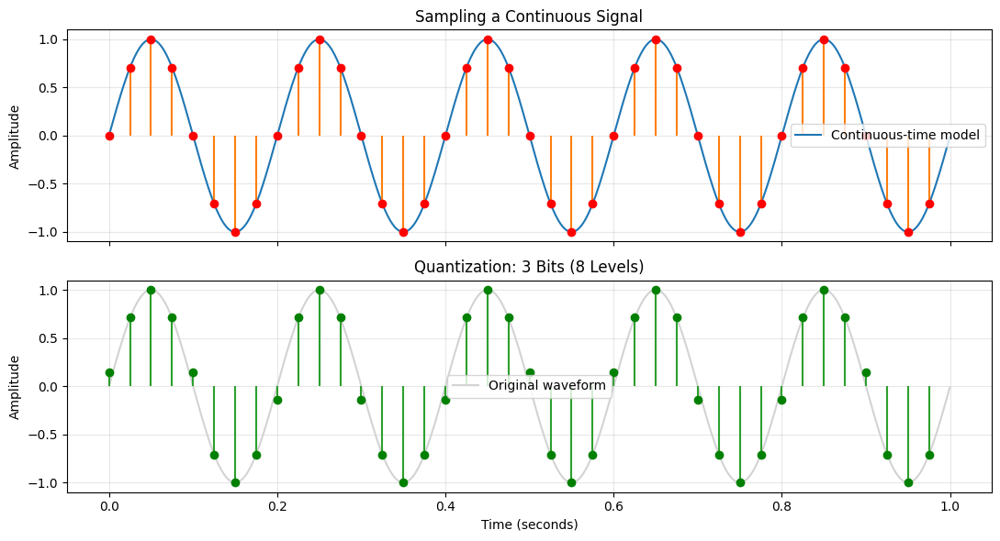

In [ ]:
# ------------------------------------------------------------
# 3. Visualization
# ------------------------------------------------------------

plot_sampling_quantization(
    t_continuous,
    x_continuous,
    t_samples,
    x_samples,
    x_quantized,
    bits
)

In [ ]:
# ------------------------------------------------------------
# 4. Inspect the Results
# ------------------------------------------------------------

print("Number of samples:", len(x_samples))
print("Sampling rate:", fs, "Hz")
print("Quantization bits:", bits)
print("Quantization levels:", levels)

print("\nFirst 10 sampled values:")
print(np.round(x_samples[:10], 3))

print("\nFirst 10 quantized values:")
print(np.round(x_quantized[:10], 3))

Number of samples: 40
Sampling rate: 40 Hz
Quantization bits: 3
Quantization levels: 8

First 10 sampled values:
[ 0.     0.707  1.     0.707  0.    -0.707 -1.    -0.707 -0.     0.707]

First 10 quantized values:
[ 0.143  0.714  1.     0.714  0.143 -0.714 -1.    -0.714 -0.143  0.714]



## **2. Mono and Stereo Audio**

Audio recordings may contain one or multiple channels.

### **2.1 Mono Audio**

Mono audio contains a single signal.

A mono recording with $N$ samples can be represented as a vector:

$$
\mathbf{x}=
\begin{bmatrix}
x_0\\
x_1\\
\vdots\\
x_{N-1}
\end{bmatrix}
\in\mathbb{R}^N.
$$

In NumPy, its shape is:

```python id="ub2e7e"
(N,)
```

### **2.2 Stereo Audio**

Stereo audio contains two channels, conventionally corresponding to left and right sound signals.

A stereo recording can be represented as a matrix:

$$
X=
\begin{bmatrix}
L_0&R_0\\
L_1&R_1\\
\vdots&\vdots\\
L_{N-1}&R_{N-1}
\end{bmatrix}
\in\mathbb{R}^{N\times2}.
$$

Each row represents a sampling instant, and each column represents an audio channel.

In NumPy, its shape is:

```python id="tw0ykb"
(N, 2)
```

### **Connection to RGB Images**

In Lab 2, each image pixel contained three color components:

$$
(R,G,B).
$$

In stereo audio, each sampling instant contains two amplitude values:

$$
(L,R).
$$

Although the physical meanings are different, both can be represented using vectors and matrices.

This allows us to apply linear algebra to audio in much the same way that we applied it to images.

-----------



# **Part A: Audio as Vectors**

A digital audio recording consists of a sequence of numerical amplitude values associated with equally spaced time intervals.

For mono audio, we represent the recording as a vector:

$$
\mathbf{x} =
\begin{bmatrix}
x_0\\
x_1\\
x_2\\
\vdots\\
x_{N-1}
\end{bmatrix}
\in \mathbb{R}^{N}.
$$

Here:

- $N$ is the total number of audio samples.
- $x_n$ is the amplitude of sample $n$.
- $f_s$ is the sampling rate (samples per second).

The time corresponding to sample $n$ is:

$$
t_n=\frac{n}{f_s}.
$$

The total recording duration is:

$$
T=\frac{N}{f_s}.
$$

## Loading Audio Using Librosa

We will use the Python library **Librosa** to load real audio recordings.

The function `librosa.load()` reads an audio file and returns:

1. A NumPy array containing the audio samples.
2. The sampling rate of the returned audio.

Its basic syntax is:

```python
audio, sr = librosa.load(path, sr=16000, mono=True)
```

The arguments are:

| Argument | Description |
|---|---|
| `path` | Path to the audio file. |
| `sr=16000` | Loads the audio at 16,000 samples per second, resampling if necessary. |
| `mono=True` | Converts multichannel audio to a single mono channel. |

The returned variables are:

- `audio`: A one-dimensional NumPy array containing the audio samples.
- `sr`: The sampling rate of the loaded audio, which is 16,000 Hz in our example.


**Note:** The stored sampling rate is not necessarily the sampling rate used when the original analog sound was recorded, because the audio may have been resampled before being saved.

## What We Will Do

In this section, we will:

1. Load and play real audio recordings.
2. Compare stored and loaded sampling rates.
3. Inspect audio vectors, their dimensions, and amplitude values.
4. Relate sample indices to time.
5. Visualize audio waveforms.
6. Extract audio segments using NumPy indexing.


In [ ]:

# ============================================================
# Demonstration 1: Loading and Inspecting Audio Vectors
# ============================================================

# ------------------------------------------------------------
# 1. Load two real audio recordings
# ------------------------------------------------------------

path_1 = librosa.ex("libri1")
path_2 = librosa.ex("libri2")

In [ ]:
# Sampling rates stored in the audio files
stored_sr_1 = librosa.get_samplerate(path_1)
stored_sr_2 = librosa.get_samplerate(path_2)

print("Stored sampling rates:")
print("Audio 1:", stored_sr_1, "Hz")
print("Audio 2:", stored_sr_2, "Hz")

Stored sampling rates:
Audio 1: 22050 Hz
Audio 2: 22050 Hz


In [ ]:
# working sampling rate
sr = 16000

# Load and resample both recordings to 16 kHz
audio_1, sr_1 = librosa.load(path_1, sr=sr, mono=True)
audio_2, sr_2 = librosa.load(path_2, sr=sr, mono=True)

print("\nSampling rates after loading:")
print("Audio 1:", sr_1, "Hz")
print("Audio 2:", sr_2, "Hz")


Sampling rates after loading:
Audio 1: 16000 Hz
Audio 2: 16000 Hz


In [ ]:
# ------------------------------------------------------------
# 2. Extract the first 5 seconds
# ------------------------------------------------------------

duration = 5

audio_1_new = audio_1[:duration * sr]
audio_2_new = audio_2[:duration * sr]

# ------------------------------------------------------------
# 3. Inspect the audio vectors
# ------------------------------------------------------------

print("\nAudio 1:")
print("Shape:", audio_1_new.shape)
print("Number of samples:", len(audio_1_new))
print("Duration:", len(audio_1_new) / sr, "seconds")
print("Data type:", audio_1_new.dtype)
print("First 10 samples:", audio_1_new[:10])

print("\nAudio 2:")
print("Shape:", audio_2_new.shape)
print("Number of samples:", len(audio_2_new))
print("Duration:", len(audio_2_new) / sr, "seconds")
print("Data type:", audio_2_new.dtype)
print("First 10 samples:", audio_2_new[:10])


Audio 1:
Shape: (80000,)
Number of samples: 80000
Duration: 5.0 seconds
Data type: float32
First 10 samples: [3.1374674e-04 3.4134480e-04 1.9113685e-04 1.5158337e-04 1.4848562e-04
 1.5254362e-04 8.6716274e-05 1.7550765e-04 8.0024598e-05 1.5249477e-04]

Audio 2:
Shape: (80000,)
Number of samples: 80000
Duration: 5.0 seconds
Data type: float32
First 10 samples: [ 5.5097616e-06 -1.9790205e-05 -2.3224879e-04 -1.8426729e-04
 -8.9437424e-05 -1.6041572e-04 -4.8893475e-04 -9.4461301e-04
 -8.0682302e-04 -3.1869870e-04]


In [ ]:
# ------------------------------------------------------------
# 4. Examine amplitude statistics
# ------------------------------------------------------------

x = audio_1_new

print("\nAudio 1 amplitude statistics:")
print("Minimum amplitude:", np.min(x))
print("Maximum amplitude:", np.max(x))
print("Mean amplitude:", np.mean(x))


Audio 1 amplitude statistics:
Minimum amplitude: -0.7793678
Maximum amplitude: 0.49958053
Mean amplitude: 9.155595e-05


In [ ]:
# ------------------------------------------------------------
# 5. Relate sample indices to time
# ------------------------------------------------------------

indices = [0, 100, 1000, 8000, 16000]
N = len(x)

print("\nSample Index | Time (s) | Amplitude")
print("-" * 40)

for n in indices:
    if n < N:
        print(f"{n:12d} | {n/sr:8.5f} | {x[n]: .6f}")


Sample Index | Time (s) | Amplitude
----------------------------------------
           0 |  0.00000 |  0.000314
         100 |  0.00625 |  0.000197
        1000 |  0.06250 |  0.000423
        8000 |  0.50000 |  0.078813
       16000 |  1.00000 | -0.060082


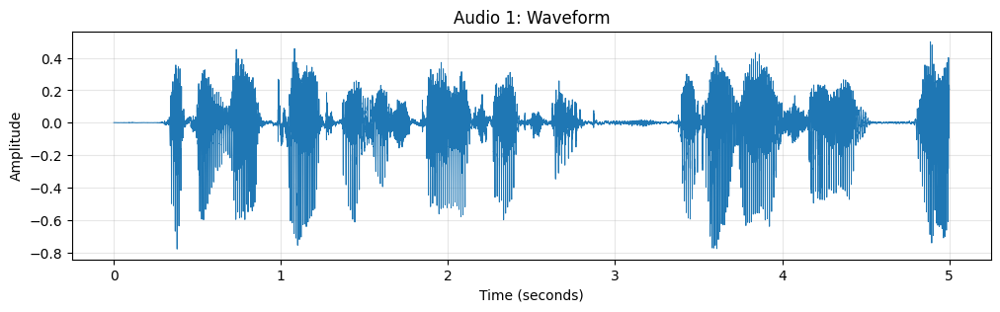

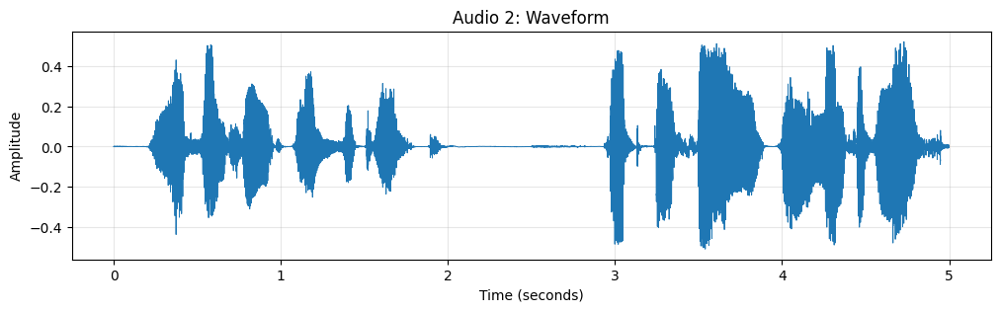

In [ ]:
# ------------------------------------------------------------
# 6. Visualize and play both recordings
# ------------------------------------------------------------

plot_waveform(audio_1_new, sr, "Audio 1: Waveform")
play_audio(audio_1_new, sr)

plot_waveform(audio_2_new, sr, "Audio 2: Waveform")
play_audio(audio_2_new, sr)


### **Understanding the 16 kHz Sampling Rate**

In Demonstration 1, we observed that both audio files have a stored sampling rate of **22,050 Hz**.

However, we loaded them using:

```python
audio, sr = librosa.load(path, sr=16000, mono=True)
```

This instructs Librosa to resample the recordings to **16,000 samples per second (16 kHz)**.

#### **Why Do We Use 16 kHz?**

A sampling rate of 16 kHz is commonly used in speech-processing and machine learning applications.

For example, some speech recognition models require audio sampled at 16 kHz as input.

Using 16 kHz provides several practical advantages:

- **Smaller data representation:** Fewer samples represent the same recording duration.
- **Lower computational requirements:** Processing fewer samples can reduce memory usage and computation.
- **Compatibility with AI models:** Many speech-processing pipelines and pretrained models use 16 kHz audio.

For this laboratory, we use 16 kHz because it is a common and computationally convenient sampling rate for speech-related AI applications.

#### **Comparing Audio Vector Dimensions**

The number of audio samples is determined by:

$$
N=f_sT,
$$

where $f_s$ is the sampling rate and $T$ is the recording duration.

Consider a 5-second recording.

**At 22,050 Hz:**

$$
N=22050\times5=110250.
$$

The audio is represented by:

$$
\mathbf{x}\in\mathbb{R}^{110250}.
$$

**At 16,000 Hz:**

$$
N=16000\times5=80000.
$$

The audio is represented by:

$$
\mathbf{y}\in\mathbb{R}^{80000}.
$$

| Property | Stored Audio | Resampled Audio |
|---|---|---|
| Sampling rate | 22,050 Hz | 16,000 Hz |
| Duration | 5 seconds | 5 seconds |
| Number of samples | 110,250 | 80,000 |
| Vector dimension | $\mathbb{R}^{110250}$ | $\mathbb{R}^{80000}$ |

The reduction in the number of samples is:

$$
\frac{110250-80000}{110250}\times100
\approx27.4\%.
$$

Therefore, resampling to 16 kHz reduces the vector dimension by approximately **27.4%** while approximately preserving the recording's duration and pitch.

Resampling may change the frequency information retained in the audio, so the two versions are not necessarily identical.

#### **Sampling Rate During Playback**

After resampling, the audio contains approximately 16,000 samples per second.

We play it using:

```python
play_audio(audio, sr)
```

Our reusable `play_audio()` function passes the sampling rate to the audio player.

It is important to distinguish:

- **Resampling:** Changes the audio samples to represent the recording at a different sampling rate while approximately preserving duration and pitch.
- **Changing only the playback rate:** Plays the same samples faster or slower, changing the duration and pitch.

#### **Key Takeaway**

*We use 16 kHz not because linear algebra requires it, but because it is a common sampling rate in speech-processing applications.*

The audio remains a numerical vector, and the same linear algebra operations can be applied regardless of the sampling rate.



## **Audio Slicing and Segmentation**

Because audio is represented as a vector, we can extract a portion of a recording using NumPy slicing.

Suppose we want to extract the audio between times $t_1$ and $t_2$.

The corresponding sample indices are:

$$
n_1=\lfloor t_1f_s\rfloor,
\qquad
n_2=\lfloor t_2f_s\rfloor.
$$

The audio segment is:

$$
\mathbf{x}_{\text{segment}}
=
\mathbf{x}[n_1:n_2].
$$

For example, if the sampling rate is 16 kHz, the segment from 1 to 2 seconds corresponds to:

$$
n_1=1(16000)=16000,
$$

$$
n_2=2(16000)=32000.
$$

Therefore:

```python
segment = audio_1[16000:32000]
```

This produces a vector containing 16,000 samples, representing one second of audio.

**Important:** NumPy slicing includes the starting index but excludes the ending index.

### Visualizing and Playing Audio Segments

We will use our reusable functions:

- `plot_waveform()` to visualize the original recording and the extracted segment.
- `plot_waveform(..., highlight=(t1, t2))` to highlight the selected interval in the original waveform.
- `play_audio()` to listen to the extracted segment.

This allows us to connect the mathematical operation of vector slicing with the corresponding portion of the audio recording.


In [ ]:

# ============================================================
# Demonstration 2: Audio Slicing and Segmentation
# ============================================================

# Select a time interval (in seconds)
start_time = 1.0
end_time = 2.5

# Convert time into sample indices
start_index = int(start_time * sr)
end_index = int(end_time * sr)

# Extract the segment using NumPy slicing
segment = audio_1[start_index:end_index]

# Inspect the extracted segment
print("Start index:", start_index)
print("End index:", end_index)
print("Segment shape:", segment.shape)
print("Number of samples:", len(segment))
print("Segment duration:", len(segment) / sr, "seconds")

Start index: 16000
End index: 40000
Segment shape: (24000,)
Number of samples: 24000
Segment duration: 1.5 seconds


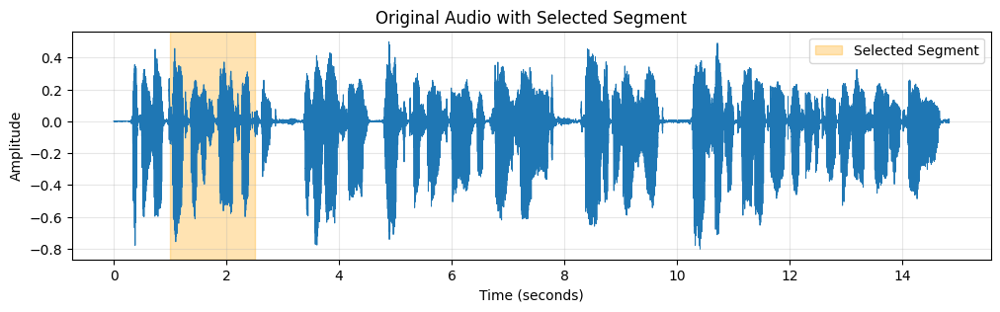

In [ ]:
# Visualize the selected interval in the original audio
plot_waveform(
    audio_1,
    sr,
    "Original Audio with Selected Segment",
    highlight=(start_time, end_time)
)


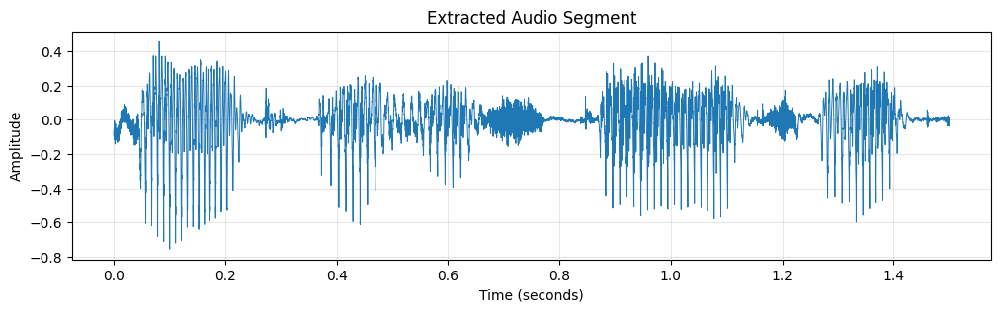

In [ ]:
# Visualize the extracted segment
plot_waveform(
    segment,
    sr,
    "Extracted Audio Segment"
)

In [ ]:
# Play the extracted segment
print("Playing extracted segment:")
play_audio(segment, sr)

Playing extracted segment:




## **Exercise 1**: Audio Vector Manipulation

Using the second audio recording (`audio_2`) loaded in Demonstration 1, complete the following tasks.

### Task 1: Audio Length and Duration

Determine:

1. The total number of samples in `audio_2`.
2. The duration of the recording in seconds.

**Hints:**
- Use `len()` or `.shape` to determine the number of samples.
- Use the sampling rate `sr` and the formula:

$$
T=\frac{N}{f_s},
$$

where $N$ is the number of samples and $f_s$ is the sampling rate.

In [ ]:

# ============================================================
# Audio Vector Manipulation
# ============================================================

# 0. Select audio_2
x = audio_2

# n,m = librosa.load(audio_2,sr=None, mono = True)
# print(n,m)
# 1. Determine the number of samples and duration
N = len(x)
T = N/sr
print(sr)
print("Number of samples:", N)
print("Duration:", T)


16000
Number of samples: 267920
Duration: 16.745


### Task 2: Audio Amplitude Statistics

Calculate and display:

1. The minimum amplitude.
2. The maximum amplitude.
3. The mean amplitude.

**Hints:**
- Use the NumPy functions `np.min()`, `np.max()`, and `np.mean()`.
- Refer to the audio vector inspection demonstrated earlier.

In [ ]:
# 2. Compute amplitude statistics
minimum = np.min(x)  # TODO
maximum = np.max(x)  # TODO
mean = np.mean(x)     # TODO

print("Minimum:", minimum)
print("Maximum:", maximum)
print("Mean:", mean)

Minimum: -0.5091546
Maximum: 0.53049517
Mean: -5.0988132e-05


### Task 3: Extract an Audio Segment

Extract the portion of `audio_2` between **2 seconds and 4 seconds**.

**Hints:**
- Convert time values into sample indices using:

$$
n=tf_s.
$$

- Use `int()` to convert the calculated indices into integers.
- Use NumPy slicing with the syntax `audio[start:end]`.

In [ ]:
# 3. Extract the segment between 2 and 4 seconds
start_index = 2*sr  # TODO
end_index = 4*sr    # TODO

segment = x[start_index:end_index]  # TODO
print(segment)

[-0.00017596 -0.00037792 -0.00030069 ...  0.0263068   0.00472075
 -0.0102927 ]


### Task 4: Visualize the Extracted Segment

Plot the waveform of the extracted audio segment.

**Hints:**
- Use the `plot_waveform()` function defined earlier in the laboratory.
- Alternatively, use `plt.plot()` from Matplotlib.
- Label the horizontal axis as **Time (seconds)** and the vertical axis as **Amplitude**.

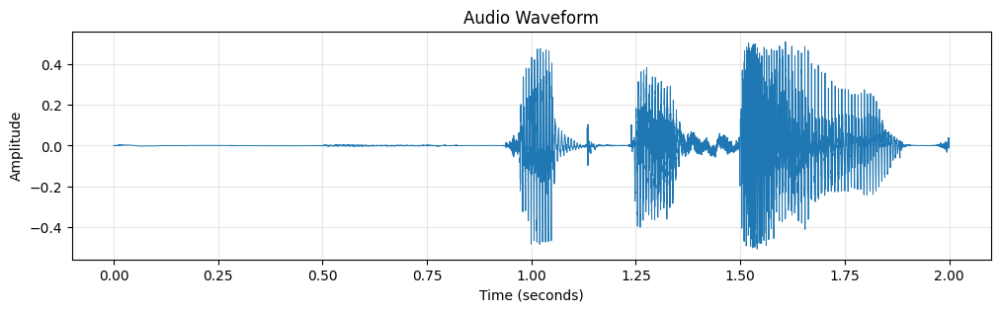

In [ ]:
# 4. Plot the segment
# TODO: Call plot_waveform()
plot_waveform(
    segment,
    sr,


)

### Task 5: Play and Compare the Audio

Play both the original recording and the extracted segment.

**Hints:**
- Use the `play_audio()` function defined earlier.
- Alternatively, use `display(Audio(signal, rate=sr))`.
- Listen to both recordings and observe how the extracted segment differs from the original in duration and content.

In [ ]:
# 5. Play the segment
# TODO: Call play_audio()
play_audio(segment,sr)

### Reflection Questions

1. How many samples should a 2-second audio segment contain when the sampling rate is 16,000 Hz?
2. Does extracting a segment change the sampling rate of the audio?
3. Why do we multiply time in seconds by the sampling rate when extracting an audio segment?

### Put your answers here:
1. 32,0000
2. NO
3. Cause sr is rate in one second so to find in total 4/5... seconds sample we multiply sr and time.



# **Part B: Vector Operations on Audio**

In Part A, we represented a mono audio recording as a vector:

$$
\mathbf{x} =
\begin{bmatrix}
x_0\\
x_1\\
\vdots\\
x_{N-1}
\end{bmatrix}
\in \mathbb{R}^{N}.
$$

Since audio is represented numerically, we can manipulate it using standard vector operations.

In this section, we will investigate:

1. **Scalar multiplication:** Adjusting audio amplitude and volume.
2. **Normalization:** Rescaling audio amplitudes.
3. **Vector addition:** Mixing two audio recordings.
4. **Noise addition:** Simulating noisy recordings.
5. **Vector norms:** Measuring audio energy and signal strength.

These operations are widely used in audio processing, speech recognition, noise reduction, and machine learning.



## **1. Scalar Multiplication: Adjusting Audio Volume**

Consider an audio signal represented by the vector:

$$
\mathbf{x} =
\begin{bmatrix}
x_0\\x_1\\ \vdots\\x_{N-1}
\end{bmatrix}.
$$

We can multiply every sample by a scalar $\alpha$:

$$
\mathbf{y}=\alpha\mathbf{x}.
$$

This gives:

$$
y_n=\alpha x_n.
$$

The scalar $\alpha$ controls the signal amplitude.

- If $0<\alpha<1$, the amplitude decreases.
- If $\alpha=1$, the signal remains unchanged.
- If $\alpha>1$, the amplitude increases.
- If $\alpha=0$, the signal becomes silent.
- If $\alpha<0$, the signal polarity is inverted.

For example, multiplying the audio vector by $0.5$ reduces every amplitude to half its original value:

$$
\mathbf{y}=0.5\mathbf{x}.
$$

**Important:** Audio samples are commonly represented using normalized floating-point values. When amplitudes exceed the valid playback range, clipping may occur and distort the sound.


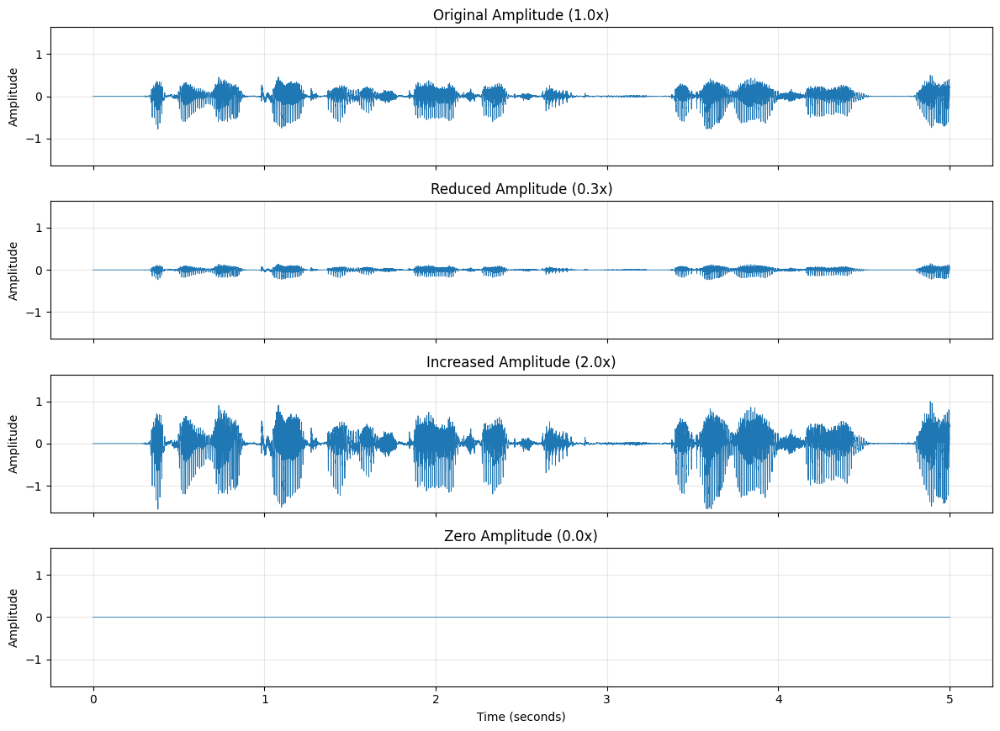

In [ ]:

# ============================================================
# Demonstration 3: Scalar Multiplication
# ============================================================

# Original audio vector
x = audio_1_new

# Apply different scaling factors
original = 1.0 * x
lower = 0.3 * x
loud = 2.0 * x
silent = 0.0 * x

# Compare waveforms using the same vertical scale
signals = [original, lower, loud, silent]

titles = [
    "Original Amplitude (1.0x)",
    "Reduced Amplitude (0.3x)",
    "Increased Amplitude (2.0x)",
    "Zero Amplitude (0.0x)"
]

compare_waveforms(signals, titles, sr)


In [ ]:
# Play the recordings in the same order
for signal, title in zip(signals, titles):
    print(f"\n{title}:")
    play_audio(signal, sr)


Original Amplitude (1.0x):



Reduced Amplitude (0.3x):



Increased Amplitude (2.0x):



Zero Amplitude (0.0x):



## **2. Audio Normalization**

Audio normalization rescales a signal according to a chosen amplitude reference.

One common method is **peak normalization**, which adjusts the maximum absolute amplitude of an audio signal to a specified value.

Given an audio vector $\mathbf{x}$, define its maximum absolute amplitude:

$$
M=\max_n |x_n|.
$$

For a nonzero signal, peak normalization to unit amplitude is:

$$
y_n=\frac{x_n}{M}.
$$

Equivalently, using vector notation:

$$
\mathbf{y}=\frac{1}{M}\mathbf{x}.
$$

This is another example of **scalar multiplication**, where every element of the vector is multiplied by the same scalar.

After normalization:

$$
\max_n |y_n|=1.
$$

For example, if the maximum absolute amplitude is $0.4$, every sample is multiplied by:

$$
\frac{1}{0.4}=2.5.
$$

This increases the signal amplitude while preserving its relative waveform shape.

If the signal consists entirely of zeros, then $M=0$. In this case, we leave the signal unchanged to avoid division by zero.

Peak normalization is useful for controlling amplitude ranges and preparing audio data for machine learning.

**Note:** Peak normalization does not guarantee that different recordings will have the same perceived loudness.


In [ ]:

# ============================================================
# Demonstration 4: Peak Normalization
# ============================================================

# Create a low-amplitude audio signal
x = 0.2 * audio_1_new

# Calculate the maximum absolute amplitude
peak = np.max(np.abs(x))

# Normalize the signal to a maximum absolute amplitude of 1
if peak > 0:
    normalized = x / peak
else:
    normalized = x.copy()

# Compare peak amplitudes
print("Peak amplitude before normalization:", peak)
print("Peak amplitude after normalization:",
      np.max(np.abs(normalized)))


Peak amplitude before normalization: 0.15587357
Peak amplitude after normalization: 1.0


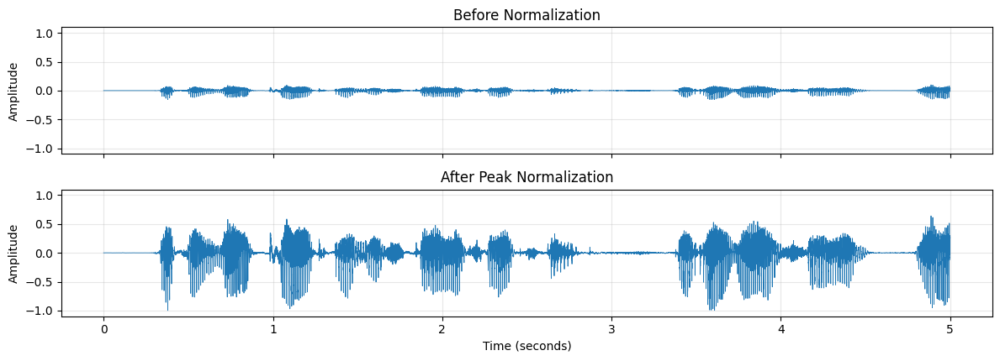

In [ ]:
# Compare waveforms using the same amplitude scale
signals = [x, normalized]

titles = [
    "Before Normalization",
    "After Peak Normalization"
]

compare_waveforms(signals, titles, sr, ylim=(-1.1, 1.1))

In [ ]:
# Play both recordings without automatic normalization
for signal, title in zip(signals, titles):
    print(f"\n{title}:")
    play_audio(signal, sr)


Before Normalization:



After Peak Normalization:



## **3. Vector Addition: Mixing Audio Signals**

Two audio recordings can be combined using vector addition.

Let:

$$
\mathbf{x},\mathbf{z}\in\mathbb{R}^{N}
$$

represent two mono audio recordings with the same sampling rate and number of samples.

Their sum is:

$$
\mathbf{y}=\mathbf{x}+\mathbf{z}.
$$

At each sample:

$$
y_n=x_n+z_n.
$$

More generally, we can use a weighted combination:

$$
\mathbf{y}=\alpha\mathbf{x}+\beta\mathbf{z}.
$$

Here, $\alpha$ and $\beta$ are scalar weights controlling the contribution of each recording.

For example:

$$
\mathbf{y}=0.5\mathbf{x}+0.5\mathbf{z}
$$

combines the two recordings with equal weights.

This is an example of a **linear combination of vectors**, involving both scalar multiplication and vector addition.

Audio mixing is used in music production, speech processing, data augmentation, and sound synthesis.

**Important considerations:**

- Both recordings must use the same sampling rate so that corresponding sample indices represent the same time intervals.
- Their vector lengths must be compatible for elementwise addition. We can extract equal-length segments using NumPy slicing.
- Mixing can produce amplitudes outside the usual playback range of $[-1,1]$, potentially causing clipping during playback.

**Note:** Mixing two mono recordings using vector addition produces another mono recording. This differs from stereo audio, where two channels are stored separately in a matrix. We will explore stereo audio in Part C.


Audio 1 shape: (237440,)
Audio 2 shape: (237440,)
Mixed audio shape: (237440,)


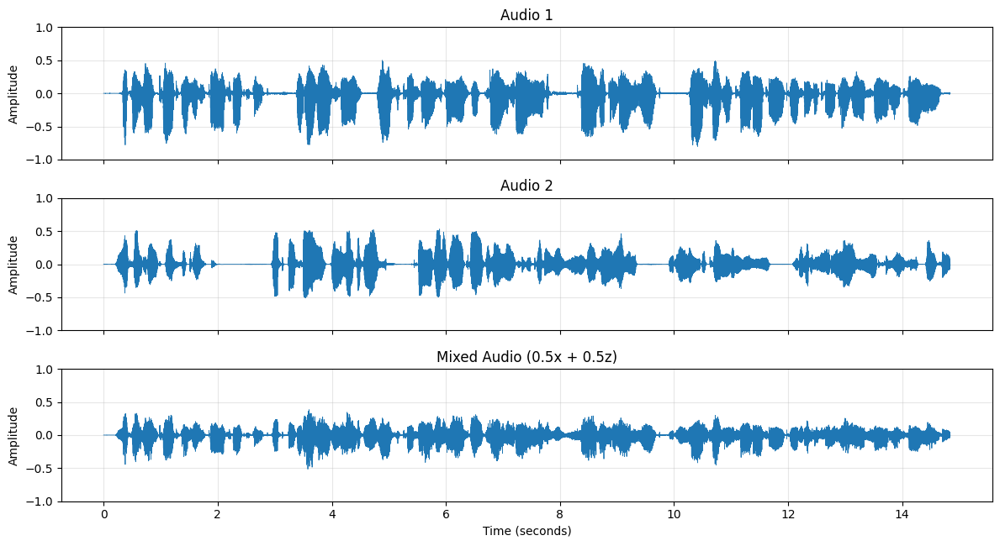

In [ ]:

# ============================================================
# Demonstration 5: Audio Mixing Using Vector Addition
# ============================================================

# Match the lengths of the two recordings
N = min(len(audio_1), len(audio_2))

x = audio_1[:N]
z = audio_2[:N]

# Weighted vector addition
mixed = 0.5 * x + 0.5 * z

# Inspect vector dimensions
print("Audio 1 shape:", x.shape)
print("Audio 2 shape:", z.shape)
print("Mixed audio shape:", mixed.shape)

# Compare the original and mixed waveforms
signals = [x, z, mixed]

titles = [
    "Audio 1",
    "Audio 2",
    "Mixed Audio (0.5x + 0.5z)"
]

compare_waveforms(signals, titles, sr)


In [ ]:
# Play the recordings in the same order
for signal, title in zip(signals, titles):
    print(f"\n{title}:")
    play_audio(signal, sr)


Audio 1:



Audio 2:



Mixed Audio (0.5x + 0.5z):



## **4. Adding Noise to Audio**

Real-world audio recordings often contain unwanted background noise.

A simple mathematical model of noisy audio is:

$$
\mathbf{y}=\mathbf{x}+\mathbf{n},
$$

where:

- $\mathbf{x}\in\mathbb{R}^{N}$ is the original audio signal.
- $\mathbf{n}\in\mathbb{R}^{N}$ is a noise vector.
- $\mathbf{y}\in\mathbb{R}^{N}$ is the resulting noisy recording.

At each sample:

$$
y_i=x_i+n_i.
$$

This is another example of **vector addition**, where the noise vector is added elementwise to the original audio vector.

### Generating Gaussian Noise

We can generate random noise whose samples follow a Gaussian (normal) distribution:


$$
n_i \sim \operatorname{Normal}(0,\sigma^2)
$$


where:

- $0$ is the mean of the noise distribution.
- $\sigma$ is the standard deviation, controlling the noise amplitude.
- $\sigma^2$ is the variance.

A larger $\sigma$ generally produces stronger noise, making the original audio more difficult to hear clearly.

In NumPy, we can generate Gaussian noise using:

```python
noise = rng.normal(loc=0.0, scale=0.05, size=len(x))
```

Here, `loc=0.0` specifies the mean, `scale=0.05` specifies the standard deviation, and `size=len(x)` ensures that the noise vector has the same number of elements as the audio vector.

Adding synthetic noise is commonly used in machine learning to test model robustness and augment training datasets.


In [ ]:

# ============================================================
# Demonstration 6: Adding Gaussian Noise
# ============================================================

# Original audio vector
x = audio_1

# Create a reproducible random number generator
rng = np.random.default_rng(42)

# Generate Gaussian noise with the same vector dimension
noise = rng.normal(loc=0.0, scale=0.05, size=len(x))

# Add noise using vector addition
noisy_audio = x + noise

# Inspect vector dimensions
print("Original audio shape:", x.shape)
print("Noise vector shape:", noise.shape)
print("Noisy audio shape:", noisy_audio.shape)


Original audio shape: (237440,)
Noise vector shape: (237440,)
Noisy audio shape: (237440,)


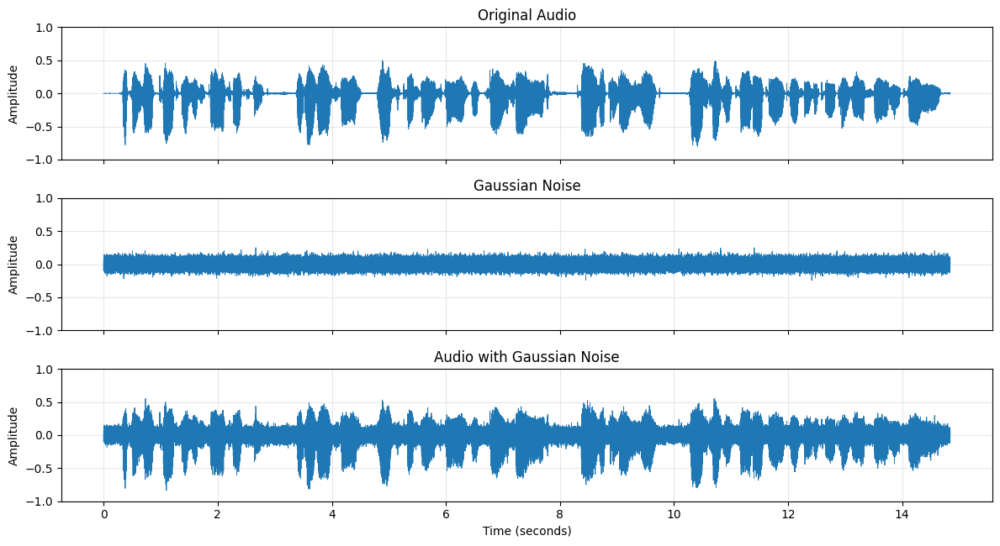

In [ ]:
# Compare waveforms using a common amplitude scale
signals = [x, noise, noisy_audio]

titles = [
    "Original Audio",
    "Gaussian Noise",
    "Audio with Gaussian Noise"
]

compare_waveforms(signals, titles, sr)

In [ ]:
# Play the original and noisy recordings
print("\nOriginal Audio:")
play_audio(x, sr)

print("\nAudio with Gaussian Noise:")
play_audio(noisy_audio, sr)


Original Audio:



Audio with Gaussian Noise:



## **5. Vector Norms and Signal Strength**

Vector norms provide mathematical tools for measuring the magnitude of an audio signal.

### 5.1 Euclidean Norm

For an audio vector:

$$
\mathbf{x}=[x_0,x_1,\ldots,x_{N-1}]^T,
$$

the **Euclidean norm**, also called the **L2 norm**, is:


$$
\|\mathbf{x}\|_2
=
\left(\sum_{n=0}^{N-1} x_n^2\right)^{1/2}
$$



It measures the overall magnitude of the audio vector.

In NumPy, we calculate it using:

```python id="45wm7u"
l2_norm = np.linalg.norm(x)
```

The **squared Euclidean norm** measures the sum of squared amplitudes:

$$
E=\|\mathbf{x}\|_2^2
=\sum_{n=0}^{N-1}x_n^2
$$

This is commonly called the signal's **discrete energy**.

```python id="55nn1r"
energy = np.sum(x ** 2)
```


### 5.3 Signal-to-Noise Ratio (SNR)

The **signal-to-noise ratio (SNR)** compares the strength of a desired signal with the strength of unwanted noise.

Suppose:

$$
\mathbf{y}=\mathbf{x}+\mathbf{n},
$$

where $\mathbf{x}$ is the original signal and $\mathbf{n}$ is the noise vector.

For equal-length vectors, SNR can be expressed in decibels (dB) as:

$$
\operatorname{SNR}_{dB}
=
10\log_{10}
\left(
\frac{\sum_i x_i^2}
{\sum_i n_i^2}
\right)
$$

A higher SNR indicates that the desired signal is stronger relative to the noise.

| SNR | Interpretation |
|---|---|
| 20 dB | Signal power is 100 times noise power. |
| 10 dB | Signal power is 10 times noise power. |
| 0 dB | Signal and noise have equal power. |
| -10 dB | Noise power is 10 times signal power. |

**Note:** SNR is undefined when both signal and noise have zero power. When noise power is zero but signal power is positive, the ideal SNR is infinite.

In the next demonstration, we will calculate these quantities using the original audio vector and the Gaussian noise generated in Demonstration 6.


In [ ]:

# ============================================================
# Demonstration 7: Vector Norms, RMS, and SNR
# ============================================================

# Original signal and noise from Demonstration 6
x = audio_1
n = noise

# ------------------------------------------------------------
# Euclidean norm and Signal energy
# ------------------------------------------------------------

l2_norm = np.linalg.norm(x)
signal_energy = np.sum(x ** 2)
noise_energy = np.sum(n ** 2)

print("Euclidean norm:", l2_norm)
print("\nSignal Energy:", signal_energy)
print("Noise Energy:", noise_energy)

Euclidean norm: 54.620193

Signal Energy: 2983.3735
Noise Energy: 595.2923406234585


In [ ]:
# ------------------------------------------------------------
# Signal-to-Noise Ratio (SNR)
# ------------------------------------------------------------

if noise_energy > 0:
    snr_from_energy = 10 * np.log10(signal_energy / noise_energy) if signal_energy > 0 else -np.inf
elif signal_energy > 0:
    snr_from_energy = np.inf
else:
    snr_from_energy = np.nan

print("SNR from energy ratio:", snr_from_energy, "dB")

SNR from energy ratio: 6.999773381766811 dB



## Exercise 2: Audio Vector Operations

Using the provided audio recordings, complete the following tasks.

1. **Scalar Multiplication:** Multiply `audio_2` by $0.25$ and $1.5$. Plot the resulting waveforms and listen to both recordings.

2. **Normalization:** Normalize `audio_2` so that its maximum absolute amplitude is 1. Verify the result numerically.

3. **Audio Mixing:** Combine `audio_1` and `audio_2` using:

   $$
   \mathbf{y}=0.7\mathbf{x}+0.3\mathbf{z}.
   $$

   Play the mixed recording.

4. **Noise Addition:** Generate Gaussian noise with standard deviation $\sigma=0.02$ and add it to `audio_2`.

5. **Signal Strength:** Compute the signal energy of the original audio, the generated noise, and the resulting SNR in decibels.

Use NumPy vector operations and the audio visualization functions defined earlier.


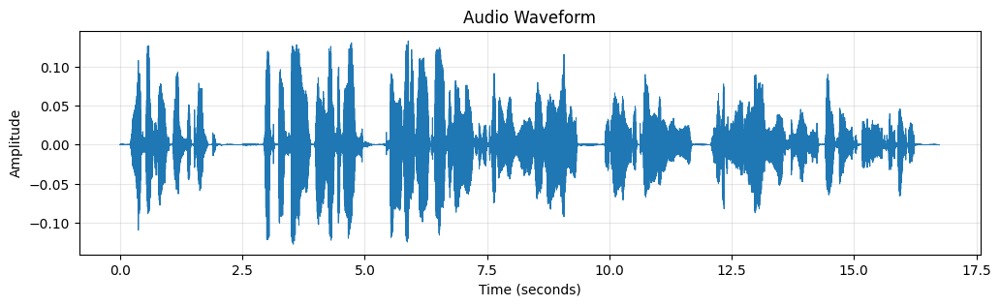

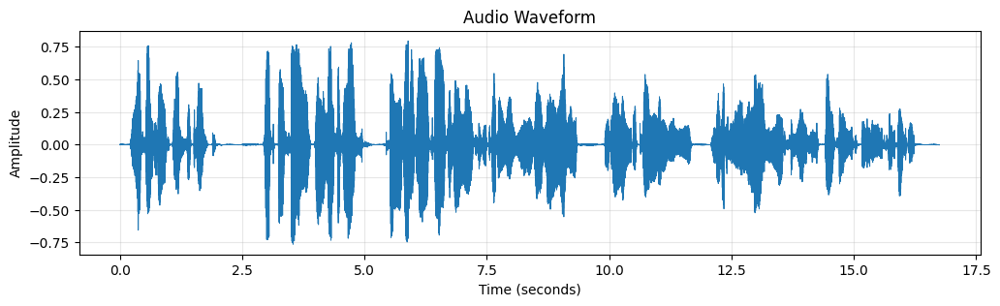

In [ ]:

# ============================================================
# Exercise 2: Audio Vector Operations
# ============================================================

# Task 1: Scalar multiplication
quiet_audio = 0.25*audio_2  # TODO: 0.25 * audio_2
loud_audio = 1.5*audio_2   # TODO: 1.5 * audio_2

# TODO: Plot and play both recordings

plot_waveform(quiet_audio)
plot_waveform(loud_audio)

In [ ]:
# Task 2: Peak normalization
peak = np.max(np.abs(audio_2))  # TODO: Maximum absolute amplitude

normalized_audio = audio_2/peak  # TODO: Normalize safely

# TODO: Verify the normalized peak
print(peak)
print(np.max(normalized_audio))

0.53049517
1.0


In [ ]:
# Task 3: Weighted audio mixing
N = min(len(audio_1), len(audio_2))

mixed_audio =  0.7 * audio_1[:N] + 0.3 * audio_2 [:N]  # TODO: 0.7 * audio_1 + 0.3 * audio_2

# TODO: Play the mixed recording
play_audio(mixed_audio)

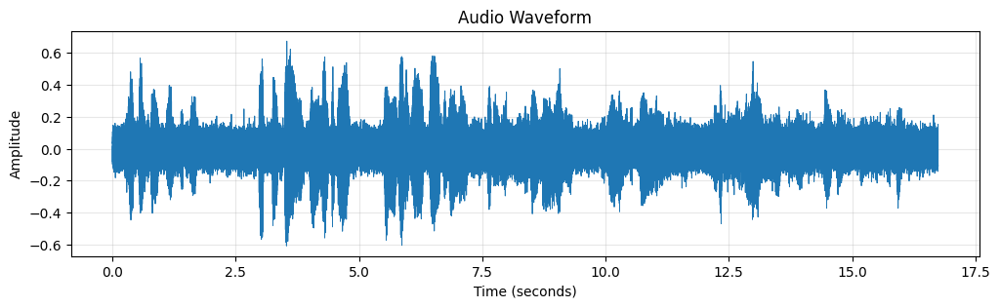

In [ ]:
# Task 4: Add Gaussian noise
rng = np.random.default_rng(42)

noise =  noise = rng.normal(loc=0.0, scale=0.05, size=len(audio_2))  # TODO: Generate Gaussian noise with std = 0.02

noisy_audio = audio_2 + noise  # TODO: Add noise to audio_2

# TODO: Plot and play the noisy recording
plot_waveform(noisy_audio)


In [ ]:
# Task 5: RMS and SNR
signal_energy = np.sum(audio_2**2)  # TODO
noise_energy = np.sum(noise**2)   # TODO

snr_db = 10 * np.log10(signal_energy / noise_energy)  # TODO


In [ ]:
print("Signal Energy:", signal_energy)
print("Noise Energy:", noise_energy)
print("SNR (dB):", snr_db)

Signal Energy: 1651.0461
Noise Energy: 671.4426483818214
SNR (dB): 3.9075028776550846


In [ ]:
pop = audio_2
test = pop * -1
ans = pop+test
play_audio(ans)


# **Part C: Audio as Matrices**

In the previous sections, we represented mono audio as a vector:

$$
\mathbf{x}\in\mathbb{R}^N.
$$

However, audio recordings may contain multiple channels.

A **stereo recording** contains two audio signals:

- **Left channel:** $\mathbf{L}\in\mathbb{R}^N$
- **Right channel:** $\mathbf{R}\in\mathbb{R}^N$

We can combine these two column vectors into a matrix:

$$
X=
\begin{bmatrix}
L_0 & R_0\\
L_1 & R_1\\
\vdots & \vdots\\
L_{N-1} & R_{N-1}
\end{bmatrix}
\in\mathbb{R}^{N\times 2}.
$$

Here:

- Each **row** represents one sampling instant.
- Each **column** represents one audio channel.
- The matrix has $N$ rows and $2$ columns.

### Matrix Representation in NumPy

We can construct the stereo matrix using:

```python id="9mx45r"
stereo = np.column_stack((left, right))
```

The resulting matrix has shape `(N, 2)`.

We can access its individual channels using matrix indexing:

```python id="m7vk4q"
left_channel = stereo[:, 0]
right_channel = stereo[:, 1]
```


### Learning Objectives

In this section, we will learn how to:

1. Construct stereo audio from two mono recordings.
2. Extract individual channels using matrix indexing.
3. Convert stereo audio to mono using channel averaging and matrix-vector multiplication.


In [ ]:

# ============================================================
# Demonstration 8: Constructing Stereo Audio
# ============================================================

# Ensure both recordings have the same number of samples
N = min(len(audio_1), len(audio_2))

# Define left and right channel vectors
left = audio_1[:N]
right = audio_2[:N]

# Construct a stereo matrix (samples, channels)
stereo = np.column_stack((left, right))

# Inspect vector and matrix dimensions
print("Left channel shape:", left.shape)
print("Right channel shape:", right.shape)
print("Stereo matrix shape:", stereo.shape)
print("Stereo matrix dimensions:", stereo.ndim)

# Inspect the first five rows
print("\nFirst five rows of the stereo matrix:")
print(stereo[:5])

Left channel shape: (237440,)
Right channel shape: (237440,)
Stereo matrix shape: (237440, 2)
Stereo matrix dimensions: 2

First five rows of the stereo matrix:
[[ 3.1374674e-04  5.5097616e-06]
 [ 3.4134480e-04 -1.9790205e-05]
 [ 1.9113685e-04 -2.3224879e-04]
 [ 1.5158337e-04 -1.8426729e-04]
 [ 1.4848562e-04 -8.9437424e-05]]


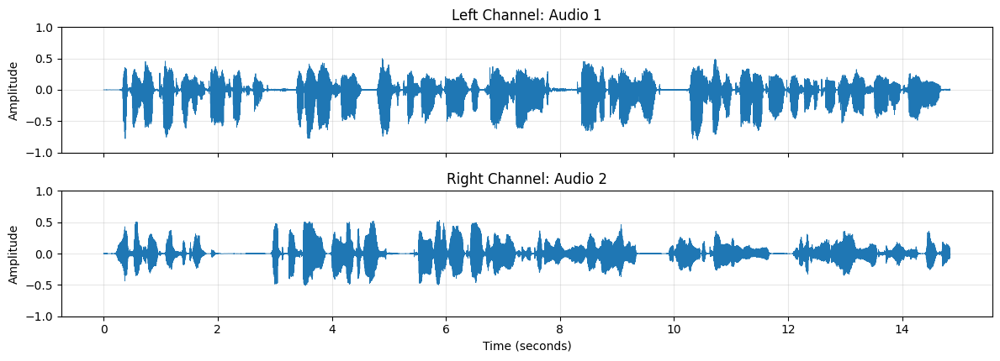

In [ ]:
# Compare left and right channel waveforms
signals = [left, right]

titles = [
    "Left Channel: Audio 1",
    "Right Channel: Audio 2"
]

compare_waveforms(signals, titles, sr)

In [ ]:
# Listen to each channel separately
print("\nLeft Channel:")
play_audio(left, sr)

print("\nRight Channel:")
play_audio(right, sr)

# Play the complete stereo recording
print("\nStereo Audio:")
play_audio(stereo, sr)


Left Channel:



Right Channel:



Stereo Audio:



## **Extracting Individual Audio Channels**

Once stereo audio is represented as a matrix, we can extract its columns using NumPy indexing.

Given the stereo matrix:

$$
X=
\begin{bmatrix}
L_0 & R_0\\
L_1 & R_1\\
\vdots & \vdots\\
L_{N-1} & R_{N-1}
\end{bmatrix}
\in\mathbb{R}^{N\times 2},
$$

the **left channel** is the first column:

$$
\mathbf{L}=X[:,0],
$$

and the **right channel** is the second column:

$$
\mathbf{R}=X[:,1].
$$

In NumPy:

```python id="95t9yu"
left_channel = stereo[:, 0]
right_channel = stereo[:, 1]
```

Each extracted channel is a vector containing $N$ samples.

### **Converting Stereo Audio to Mono**

We can combine the left and right channels to produce a single mono audio signal.

A common downmixing operation is to calculate the average amplitude at each sampling instant:

$$
m_n=\frac{L_n+R_n}{2}.
$$

In vector form:

$$
\mathbf{m}
=
0.5\mathbf{L}+0.5\mathbf{R}.
$$

This is a **linear combination** of the two channel vectors.

### **Stereo-to-Mono Conversion Using Matrix Multiplication**

The same operation can be expressed using matrix-vector multiplication:

$$
\mathbf{m}
=
X
\begin{bmatrix}
0.5\\
0.5
\end{bmatrix}.
$$

In NumPy, matrix-vector multiplication is performed using the `@` operator:

```python id="w5a4kb"
weights = np.array([0.5, 0.5])
mono = stereo @ weights
```

The resulting `mono` array has shape `(N,)`.

**Important:** Stereo-to-mono conversion loses the distinction between the original left and right channels. If the channels contain opposite amplitudes, averaging may also cause partial or complete cancellation.


In [ ]:

# ============================================================
# Demonstration 9: Channel Extraction and Mono Conversion
# ============================================================

# ------------------------------------------------------------
# 1. Extract individual channels using matrix indexing
# ------------------------------------------------------------

left_channel = stereo[:, 0]
right_channel = stereo[:, 1]

print("Stereo matrix shape:", stereo.shape)
print("Left channel shape:", left_channel.shape)
print("Right channel shape:", right_channel.shape)


Stereo matrix shape: (237440, 2)
Left channel shape: (237440,)
Right channel shape: (237440,)


In [ ]:
# ------------------------------------------------------------
# 2. Convert stereo to mono using matrix-vector multiplication
# ------------------------------------------------------------

weights = np.array([0.5, 0.5])

mono = stereo @ weights

print("\nWeight vector shape:", weights.shape)
print("Mono audio shape:", mono.shape)


Weight vector shape: (2,)
Mono audio shape: (237440,)


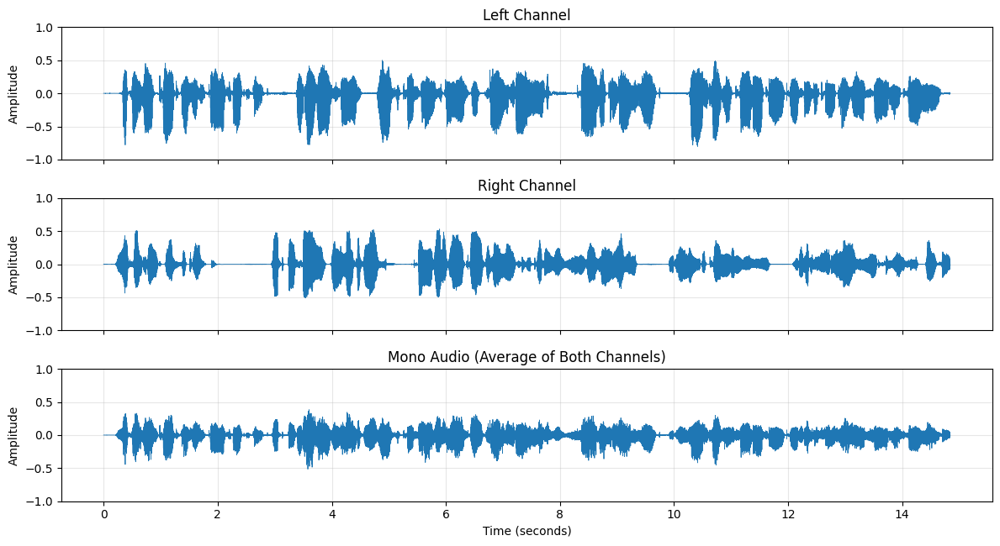

In [ ]:
# ------------------------------------------------------------
# 3. Compare the channel and mono waveforms
# ------------------------------------------------------------

signals = [left_channel, right_channel, mono]

titles = [
    "Left Channel",
    "Right Channel",
    "Mono Audio (Average of Both Channels)"
]

compare_waveforms(signals, titles, sr)

In [ ]:
# ------------------------------------------------------------
# 4. Listen to the original stereo and converted mono audio
# ------------------------------------------------------------

print("\nOriginal Stereo Audio:")
play_audio(stereo, sr)

print("\nConverted Mono Audio:")
play_audio(mono, sr)


Original Stereo Audio:



Converted Mono Audio:



## **Exercise 3**: Stereo Audio and Channel Operations


Using `audio_1` and `audio_2`, complete the following tasks.

### Task 1: Construct a Stereo Recording

1. Ensure that both recordings have the same number of samples.
2. Place `audio_2` in the left channel and `audio_1` in the right channel.
3. Combine the two vectors into a stereo matrix using `np.column_stack()`.
4. Print the shape of the resulting matrix and play the stereo recording.

Stereo matrix shape: [[ 5.5097616e-06  3.1374674e-04]
 [-1.9790205e-05  3.4134480e-04]
 [-2.3224879e-04  1.9113685e-04]
 ...
 [-3.4169185e-03 -1.7738744e-03]
 [-2.9027006e-03  1.5042410e-03]
 [-7.0014014e-03  2.3349633e-03]]


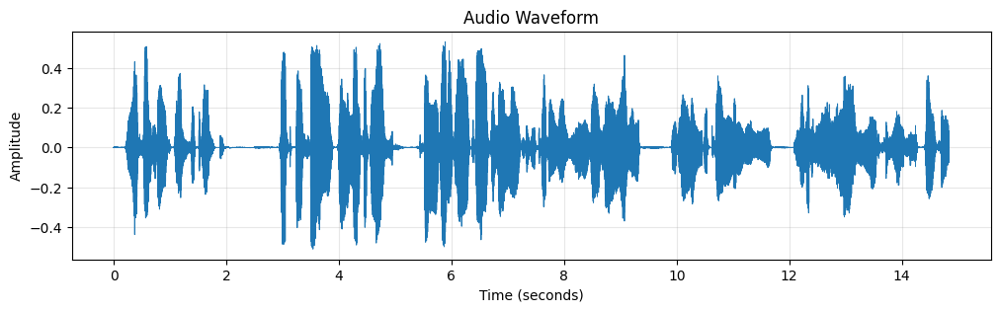

In [ ]:
# ============================================================
# Exercise 3: Stereo Audio and Channel Operations
# ============================================================

# ------------------------------------------------------------
# Task 1: Construct a Stereo Recording
# ------------------------------------------------------------

# Determine the common number of samples
N = min(len(audio_1),len(audio_2))  # TODO

# Extract equal-length recordings
left = audio_2[:N]   # TODO: Use audio_2
right = audio_1[:N]  # TODO: Use audio_1

# Construct stereo matrix
stereo_ex = np.column_stack((left,right))  # TODO: Use np.column_stack()

print("Stereo matrix shape:", stereo_ex)  # TODO

# TODO: Play stereo audio using IPython Audio

play_audio(stereo_ex)
plot_waveform(left)

### Task 2: Extract Individual Channels

1. Extract the left and right channels from the stereo matrix.
2. Print their shapes.
3. Plot the waveform of each channel.
4. Play each channel separately.

Left channel shape: [ 5.5097616e-06 -1.9790205e-05 -2.3224879e-04 ... -3.4169185e-03
 -2.9027006e-03 -7.0014014e-03]
Right channel shape: [ 0.00031375  0.00034134  0.00019114 ... -0.00177387  0.00150424
  0.00233496]


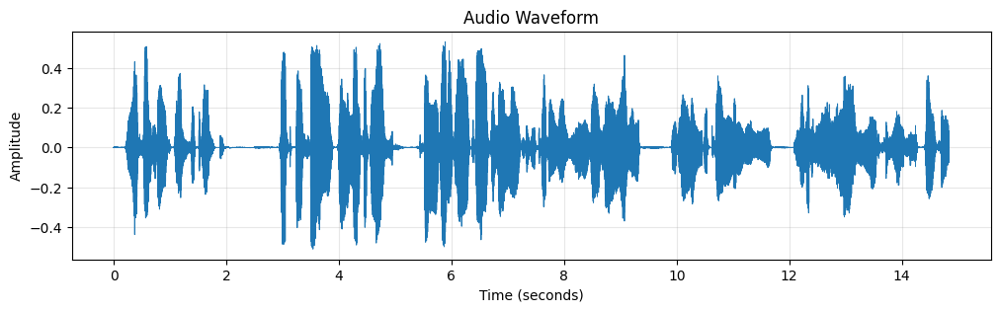

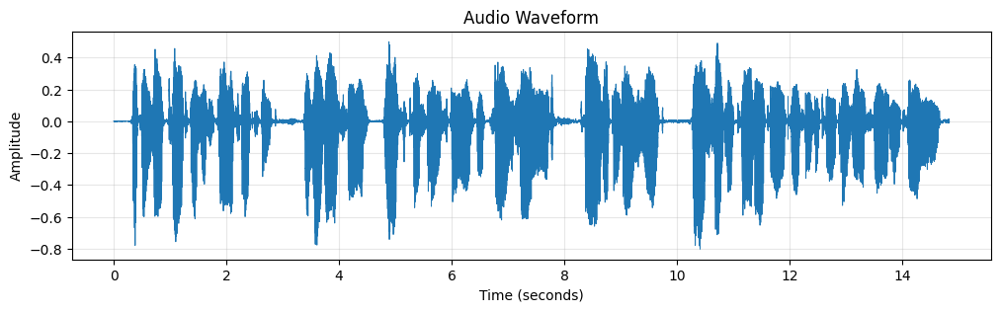

In [ ]:
# ------------------------------------------------------------
# Task 2: Extract Individual Channels
# ------------------------------------------------------------

left_channel = stereo_ex[:,0]   # TODO
right_channel = stereo_ex[:,1]  # TODO

print("Left channel shape:", left_channel)   # TODO
print("Right channel shape:", right_channel)  # TODO

# TODO: Plot both waveforms using plot_waveform()
plot_waveform(left_channel)
plot_waveform(right_channel)

# TODO: Play each channel using play_audio_raw()
play_audio(left_channel,sr)

play_audio(right_channel,sr)


### Task 3: Convert Stereo to Mono

Convert the stereo recording into mono by averaging its two channels:

$$
m_n=\frac{L_n+R_n}{2}.
$$

1. Compute the mono signal using NumPy.
2. Print its shape.
3. Plot and play the mono recording.
4. Compare its sound with the original stereo recording.


Mono shape: [ 1.5962825e-04  1.6077730e-04 -2.0555970e-05 ... -2.5953965e-03
 -6.9922977e-04 -2.3332192e-03]


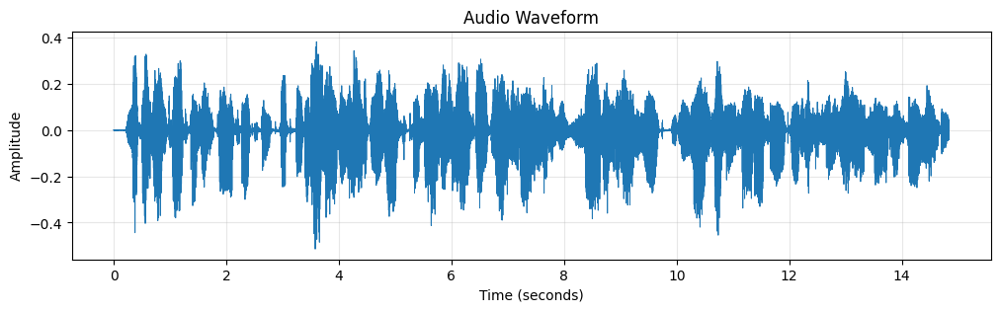

In [ ]:
# ------------------------------------------------------------
# Task 3: Convert Stereo to Mono
# ------------------------------------------------------------

mono_audio =(left_channel + right_channel )/2 # TODO: Average the two channels

print("Mono shape:", mono_audio)  # TODO

# TODO: Plot the mono waveform
plot_waveform(mono_audio)
# TODO: Play the mono recording
play_audio(mono_audio)

### Task 4: Verify the Conversion

Verify that the mono recording obtained by averaging the channels is equivalent to the result of the matrix-vector multiplication:

$$
\mathbf{m}
=
X
\begin{bmatrix}
0.5\\
0.5
\end{bmatrix}.
$$

Use `np.allclose()` to compare the two results.

In [ ]:
# ------------------------------------------------------------
# Task 4: Verify Using Matrix-Vector Multiplication
# ------------------------------------------------------------

weights = np.array([0.5, 0.5])

mono_matrix = stereo_ex @ weights  # TODO: Matrix-vector multiplication

print(mono_matrix)
# Verify equivalence
result =  np.allclose(mono_audio,mono_matrix) # TODO: Use np.allclose()

print("Both methods produce the same result:", result)

[ 1.59628252e-04  1.60777297e-04 -2.05559700e-05 ... -2.59539642e-03
 -6.99229771e-04 -2.33321905e-03]
Both methods produce the same result: True



# **Lab 3 Summary: Audio Data and Linear Algebra**

In this laboratory, we explored how digital audio can be represented and manipulated using mathematical vectors and matrices.

The concepts introduced in this laboratory are fundamental to many AI applications:

- **Speech recognition:** Audio recordings are converted into numerical representations that machine learning models can process.
- **Audio classification:** Models analyze audio data to recognize sounds, speakers, or acoustic events.
- **Data preprocessing:** Normalization, segmentation, and channel conversion prepare audio for machine learning.
- **Data augmentation:** Adding noise or combining recordings can help construct varied training examples.

### **Key Takeaway**

Images and audio have different physical meanings, but both can be represented as numerical arrays.

Once data is represented numerically, mathematical operations such as vector addition, scalar multiplication, norms, and matrix-vector multiplication become useful tools for processing and analyzing it.

This illustrates an important principle of Mathematics for AI:

**Different types of data can be studied using common mathematical structures and operations.**
